# 10 · FleetWatch: ship-level tracking of the listed fleets

**What is proprietary here** is not raw AIS - large funds buy that - but the mapping from
named ships to listed owners, and the company-level operating estimates built on it for
small-cap names that few analysts model.

| Layer | Source | Status |
|---|---|---|
| Fleet register: company -> ship, DWT, built, employment | SEC 20-F/10-K fleet tables, Diana fleet employment 6-K, company fleet pages | ~1,000 operating ships, 21 owners |
| AIS identity (MMSI/IMO) | aisstream.io static reports | builds as the collector runs |
| Ship states: laden/ballast, underway/anchored/moored, region | AIS positions + draught, PortWatch port list | builds as the collector runs |
| Company signals: idle share, laden share, regional exposure | aggregation of ship states | forward-only, committed hourly |

Every estimate is written to git by a scheduled job before the company reports, so the live
record cannot be fitted afterwards.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, matplotlib.pyplot as plt
from shiplab import style
from shiplab.config import DATA, REFERENCE
reg = pd.read_csv(REFERENCE / "fleet_register.csv")
op = reg[~reg.newbuild]
op.groupby(["segment", "universe_id"]).agg(ships=("vessel", "size"), dwt_m=("dwt", lambda x: x.sum() / 1e6),
                                           median_age=("built", lambda b: 2026 - b.median())).round(1)

ships  dwt_m  median_age
segment  universe_id                          
dry_bulk CMDB            49    5.0        14.0
         CTRM             8    0.6        12.5
         DSX             36    4.1        13.0
         EDRY            13    0.9        12.0
         GNK             43    4.6        12.0
         PANL            39    2.3        12.0
         SB              46    4.6        12.0
         SBLK           135   13.6        13.0
         SHIP            19    3.5        15.0
tankers  ASC             26    1.2        11.0
         DHT             22    6.8        10.0
         FRO             80   17.6         9.0
         HAFNI           99    6.4        10.0
         INSW            65    7.6        11.0
         NAT             20    3.2        12.5
         OET             14    3.5         7.0
         PSHG_T          10    1.2        14.0
         STNG            90    6.4        11.0
         TEN             62    7.9        10.0
         TNK             34    4.5        15.0
         TRMD            93    6.3        13.0

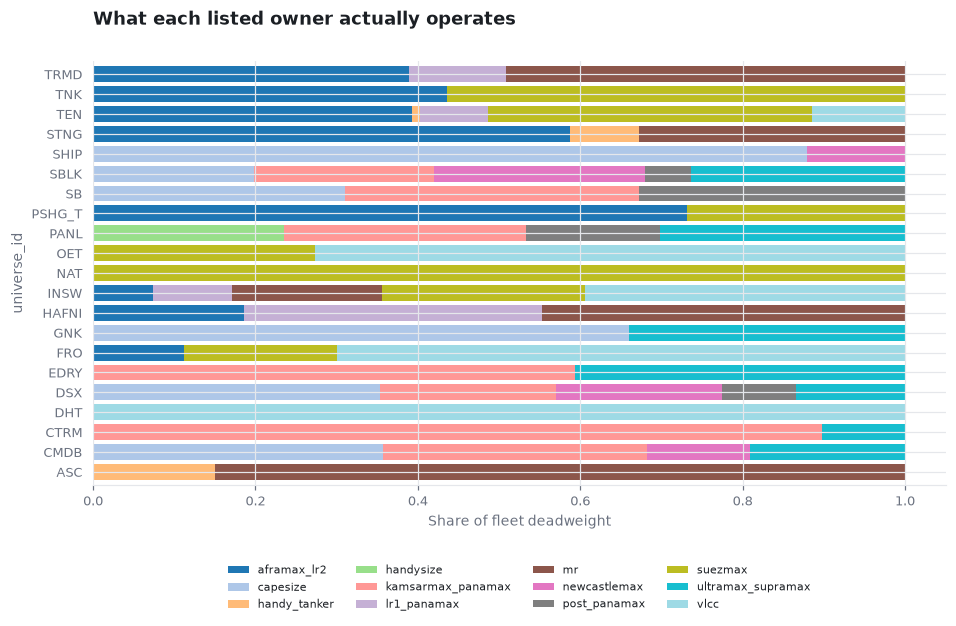

In [2]:
style.apply()
mix = op.pivot_table(index="universe_id", columns="vessel_class", values="dwt", aggfunc="sum").fillna(0)
mix = mix.div(mix.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10, 5))
mix.sort_index().plot.barh(stacked=True, ax=ax, width=0.8, colormap="tab20")
ax.set_xlabel("Share of fleet deadweight")
ax.legend(ncol=4, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, -0.32))
ax.set_title("What each listed owner actually operates"); plt.show()

In [3]:
ident = DATA / "fleet" / "identity.csv"
sig = DATA / "fleet" / "company_signals.csv"
if ident.exists():
    display(pd.read_csv(ident)["status"].value_counts())
if sig.exists():
    display(pd.read_csv(sig).tail(20))
else:
    print("Live collection not yet started: signals appear here once the hourly collector has run.")

Live collection not yet started: signals appear here once the hourly collector has run.
